# Exploratory Data Analysis: Hotel Booking Cancellations

## Goal of this notebook

Before training any model we need to understand the data we are working with. This notebook answers five questions:

1. **Structure:** What does one row describe, and which kinds of columns do we have?
2. **Target:** How are canceled and non-canceled bookings distributed?
3. **Data quality:** Are there missing values, duplicate rows or impossible records?
4. **Relationships:** Which features are related to cancellation?
5. **Pitfalls:** Are there features that leak the answer, or patterns that change over time?

Every finding ends with a **decision** for preprocessing or modeling. The last section collects all of them in one table.

## The data

The *Hotel Booking Demand* dataset (Antonio, Almeida & Nunes, 2019, *Data in Brief*; distributed on Kaggle) contains real bookings from two hotels in Portugal: a **resort hotel** in the Algarve and a **city hotel** in Lisbon. Arrivals range from July 2015 to August 2017. Personal information has been removed.

**Prediction task:** predict, at the moment a booking is made, whether it will be canceled (`is_canceled`: 1 = canceled, 0 = not canceled).

## 0. Setup

In [3]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import chi2_contingency

PROJECT_ROOT = Path.cwd().parent
if str(PROJECT_ROOT) not in sys.path:
    sys.path.append(str(PROJECT_ROOT))

from src.load_data import load_data

# Show all columns and round floats in tables
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", "{:,.2f}".format)

# Plot style: light grid, no top/right frame, readable font sizes
plt.rcParams.update({
    "figure.dpi": 110,
    "font.size": 11,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "axes.axisbelow": True,
})

# One fixed color per meaning, used in every chart
BLUE = "#2a78d6"     # not canceled / below the average cancellation rate
ORANGE = "#eb6834"   # canceled / above the average cancellation rate
AQUA = "#1baf7a"     # second hotel in hotel comparisons
GRAY = "#8a8a85"     # reference lines

In [4]:
df = load_data()
df.shape

(119390, 32)

In [5]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 119390 entries, 0 to 119389
Data columns (total 32 columns):
 #   Column                          Non-Null Count   Dtype  
---  ------                          --------------   -----  
 0   hotel                           119390 non-null  str    
 1   is_canceled                     119390 non-null  int64  
 2   lead_time                       119390 non-null  int64  
 3   arrival_date_year               119390 non-null  int64  
 4   arrival_date_month              119390 non-null  str    
 5   arrival_date_week_number        119390 non-null  int64  
 6   arrival_date_day_of_month       119390 non-null  int64  
 7   stays_in_weekend_nights         119390 non-null  int64  
 8   stays_in_week_nights            119390 non-null  int64  
 9   adults                          119390 non-null  int64  
 10  children                        119386 non-null  float64
 11  babies                          119390 non-null  int64  
 12  meal                       

In [7]:
numerical_columns = df.select_dtypes(include="number").columns.tolist()
categorical_columns = df.select_dtypes(exclude="number").columns.tolist()

print(f"Numerical columns   ({len(numerical_columns)}): {numerical_columns}\n")
print(f"Categorical columns ({len(categorical_columns)}): {categorical_columns}")

Numerical columns   (20): ['is_canceled', 'lead_time', 'arrival_date_year', 'arrival_date_week_number', 'arrival_date_day_of_month', 'stays_in_weekend_nights', 'stays_in_week_nights', 'adults', 'children', 'babies', 'is_repeated_guest', 'previous_cancellations', 'previous_bookings_not_canceled', 'booking_changes', 'agent', 'company', 'days_in_waiting_list', 'adr', 'required_car_parking_spaces', 'total_of_special_requests']

Categorical columns (12): ['hotel', 'arrival_date_month', 'meal', 'country', 'market_segment', 'distribution_channel', 'reserved_room_type', 'assigned_room_type', 'deposit_type', 'customer_type', 'reservation_status', 'reservation_status_date']


### Interpretation

- Each row is **one booking**: 119,390 bookings and 32 columns (31 features + the target).
- 20 columns are stored as numbers and 12 as text. Without the target this is **19 numerical and 12 categorical features**.
- **Not every number is a quantity.** `agent` and `company` are stored as numbers, but they are **ID codes**: agent 240 is not "bigger" than agent 9. We will treat them as categories.
- `children` is stored as a decimal number (`float64`) although child counts are whole numbers. The reason is missing values.
- `is_repeated_guest` and `is_canceled` are 0/1 flags stored as numbers.

In [11]:
target = pd.DataFrame({
    "bookings": df["is_canceled"].value_counts(),
    "share": df["is_canceled"].value_counts(normalize=True),
}).rename(index={0: "Not canceled", 1: "Canceled"})
target

,bookings,share
is_canceled,,
Not canceled,75166,0.63
Canceled,44224,0.37


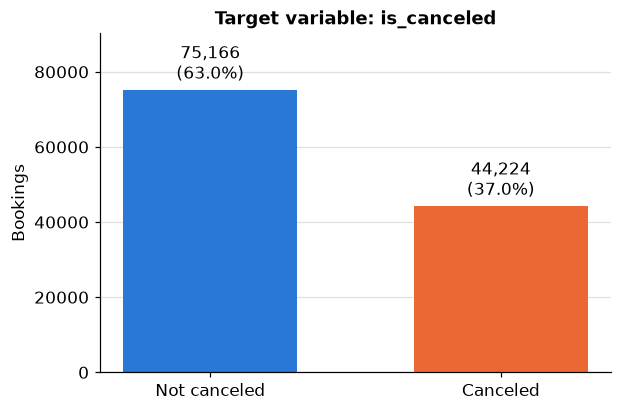

In [12]:
fig, ax = plt.subplots(figsize=(6, 4))
bars = ax.bar(target.index, target["bookings"], color=[BLUE, ORANGE], width=0.6)
for bar, (count, share) in zip(bars, target.values):
    ax.text(bar.get_x() + bar.get_width() / 2, count + 1500,
            f"{count:,.0f}\n({share:.1%})", ha="center", va="bottom")
ax.set_ylim(0, target["bookings"].max() * 1.2)
ax.set_ylabel("Bookings")
ax.set_title("Target variable: is_canceled")
plt.show()

In [13]:
majority_baseline = df["is_canceled"].value_counts(normalize=True).max()
print(f"Accuracy of always predicting 'not canceled': {majority_baseline:.1%}")

Accuracy of always predicting 'not canceled': 63.0%


### Interpretation

- **63.0%** of bookings are not canceled and **37.0%** are canceled: a **binary classification** problem with a **mild class imbalance**.
- Predicting "not canceled" for everyone already gives **63% accuracy** while catching zero cancellations. Accuracy alone would therefore be misleading.

**Decision:** evaluate models with **F1-score** and **ROC-AUC**, and use **stratified** splits so that train and test keep the same cancellation rate.

## 3. Missing values

**What we do:** count missing values per column, then ask *what* a missing value means in each case.

**Why:** a missing value is not always an error. Sometimes "empty" carries information (for example "no company"), and how we fill it depends on that meanin

In [14]:
missing = df.isna().sum()
missing = missing[missing > 0].sort_values(ascending=False)

missing_table = pd.DataFrame({
    "missing_values": missing,
    "percent": 100 * missing / len(df),
})
missing_table

,missing_values,percent
company,112593,94.31
agent,16340,13.69
country,488,0.41
children,4,0.00


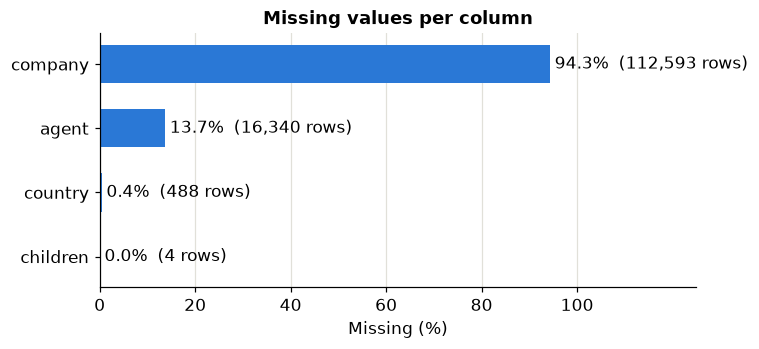

In [15]:
fig, ax = plt.subplots(figsize=(7, 3))
ax.barh(missing_table.index[::-1], missing_table["percent"][::-1], color=BLUE, height=0.6)
for y, (count, pct) in enumerate(missing_table[["missing_values", "percent"]].values[::-1]):
    ax.text(pct + 1, y, f"{pct:.1f}%  ({count:,.0f} rows)", va="center")
ax.set_xlim(0, 125)
ax.set_xticks(range(0, 101, 20))
ax.set_xlabel("Missing (%)")
ax.set_title("Missing values per column")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
plt.show()

In [16]:
missing_meaning = pd.DataFrame({
    col: df.groupby(df[col].isna())["is_canceled"].mean()
    for col in ["agent", "company"]
}).rename(index={False: "value present", True: "value missing"})
missing_meaning.style.format("{:.1%}")

,agent,company
value present,39.0%,17.5%
value missing,24.7%,38.2%


### Interpretation

| Column | Missing | Likely meaning | Decision |
|---|---|---|---|
| `company` | 94.3% | The booking was **not** made through a company | Keep; fill with a `"None"` category |
| `agent` | 13.7% | The booking was **not** made through a travel agent | Keep; fill with a `"None"` category |
| `country` | 0.4% | Unknown country | Fill with `"Unknown"` |
| `children` | 4 rows | Probably 0 | Fill with 0 and convert to integer |

- Missing `company` / `agent` values are **not random**: cancellation rates differ clearly between bookings with and without them. The missing value itself is information, so we **keep it as its own category** instead of dropping the column or the rows.
- This also explains why `children` is a decimal column (see Section 1).

## 4. Data quality: duplicates and impossible records

### 4.1 Duplicate rows

**What we do:** find rows that are identical in every column.

**Why:** if the same row ends up in both the training set and the test set, the model is tested on a row it has already seen and the score looks better than it really is.

`duplicated()` marks every copy **after the first one**, i.e. the rows we would delete. `duplicated(keep=False)` marks **all** rows that belong to a duplicate group, including the first copy.

In [17]:
extra_copies = df.duplicated()
in_duplicate_group = df.duplicated(keep=False)

group_sizes = df[in_duplicate_group].value_counts(dropna=False)

pd.Series({
    "rows": f"{len(df):,}",
    "extra copies (would be removed)": f"{extra_copies.sum():,}",
    "extra copies (%)": f"{100 * extra_copies.mean():.1f}%",
    "rows belonging to a duplicate group": f"{in_duplicate_group.sum():,}",
    "number of duplicate groups": f"{len(group_sizes):,}",
    "largest group (rows)": f"{group_sizes.max():,}",
}).to_frame("value")

,value
rows,"119,390"
extra copies (would be removed),"31,994"
extra copies (%),26.8%
rows belonging to a duplicate group,"40,165"
number of duplicate groups,"8,171"
largest group (rows),180


In [18]:
pd.DataFrame({
    "cancel_rate_all_rows": [df["is_canceled"].mean()],
    "cancel_rate_after_removing_duplicates": [df.drop_duplicates()["is_canceled"].mean()],
    "cancel_rate_inside_duplicate_groups": [df.loc[in_duplicate_group, "is_canceled"].mean()],
}).style.format("{:.1%}")

,cancel_rate_all_rows,cancel_rate_after_removing_duplicates,cancel_rate_inside_duplicate_groups
0,37.0%,27.5%,58.4%


### 4.2 Impossible or suspicious records

**What we do:** look for bookings that cannot exist: nobody staying, zero nights, or a price of zero or less.

**Why:** these are either data-entry errors or special cases (e.g. free rooms) that do not represent a normal booking.

In [19]:
total_guests = df["adults"] + df["children"].fillna(0) + df["babies"]
total_nights = df["stays_in_weekend_nights"] + df["stays_in_week_nights"]

checks = {
    "zero guests": total_guests == 0,
    "zero nights": total_nights == 0,
    "price (adr) = 0": df["adr"] == 0,
    "price (adr) < 0": df["adr"] < 0,
}
any_problem = pd.concat(checks, axis=1).any(axis=1)

pd.Series({name: mask.sum() for name, mask in checks.items()}
          | {"rows with at least one problem": any_problem.sum()}).to_frame("rows")

,rows
zero guests,180
zero nights,715
price (adr) = 0,1959
price (adr) < 0,1
rows with at least one problem,1991


### Interpretation

- **31,994 rows (26.8%)** are exact copies. They form 8,171 groups, the largest with 180 identical rows. The dataset has no customer ID, so these may be real separate bookings (for example a group reserving many identical rooms) or recording errors; we cannot tell which.
- Duplicates are concentrated among canceled bookings: removing them lowers the cancellation rate from **37.0% to 27.5%**.
- About **2,000 rows** are impossible or suspicious: zero guests, zero nights, or a price of zero or less. Some zero prices are complimentary rooms. One booking has a price of **€5,400 per night**, far above all others (next highest: €510): a clear error.

**Decisions:**
- **Remove duplicate rows before splitting** into train and test (main pipeline). If time allows, compare with keeping them and splitting by duplicate group.
- **Remove** zero-guest, zero-night and non-positive-price bookings and the €5,400 outlier.
- Report the cancellation rate after cleaning (~27.5%), not only the raw 37%.

### 5. Numerical features: distributions and outliers

In [20]:
key_numerical = [
    "lead_time", "adr", "stays_in_weekend_nights", "stays_in_week_nights",
    "adults", "children", "babies", "previous_cancellations",
    "previous_bookings_not_canceled", "booking_changes",
    "days_in_waiting_list", "required_car_parking_spaces", "total_of_special_requests",
]
summary = df[key_numerical].describe().T
summary["share_of_zeros"] = (df[key_numerical] == 0).mean()
summary

,count,mean,std,min,25%,50%,75%,max,share_of_zeros
lead_time,"119,390.00",104.01,106.86,0.00,18.00,69.00,160.00,737.00,0.05
adr,"119,390.00",101.83,50.54,-6.38,69.29,94.58,126.00,"5,400.00",0.02
stays_in_weekend_nights,"119,390.00",0.93,1.00,0.00,0.00,1.00,2.00,19.00,0.44
stays_in_week_nights,"119,390.00",2.50,1.91,0.00,1.00,2.00,3.00,50.00,0.06
adults,"119,390.00",1.86,0.58,0.00,2.00,2.00,2.00,55.00,0.00
children,"119,386.00",0.10,0.40,0.00,0.00,0.00,0.00,10.00,0.93
babies,"119,390.00",0.01,0.10,0.00,0.00,0.00,0.00,10.00,0.99
previous_cancellations,"119,390.00",0.09,0.84,0.00,0.00,0.00,0.00,26.00,0.95
previous_bookings_not_canceled,"119,390.00",0.14,1.50,0.00,0.00,0.00,0.00,72.00,0.97
booking_changes,"119,390.00",0.22,0.65,0.00,0.00,0.00,0.00,21.00,0.85


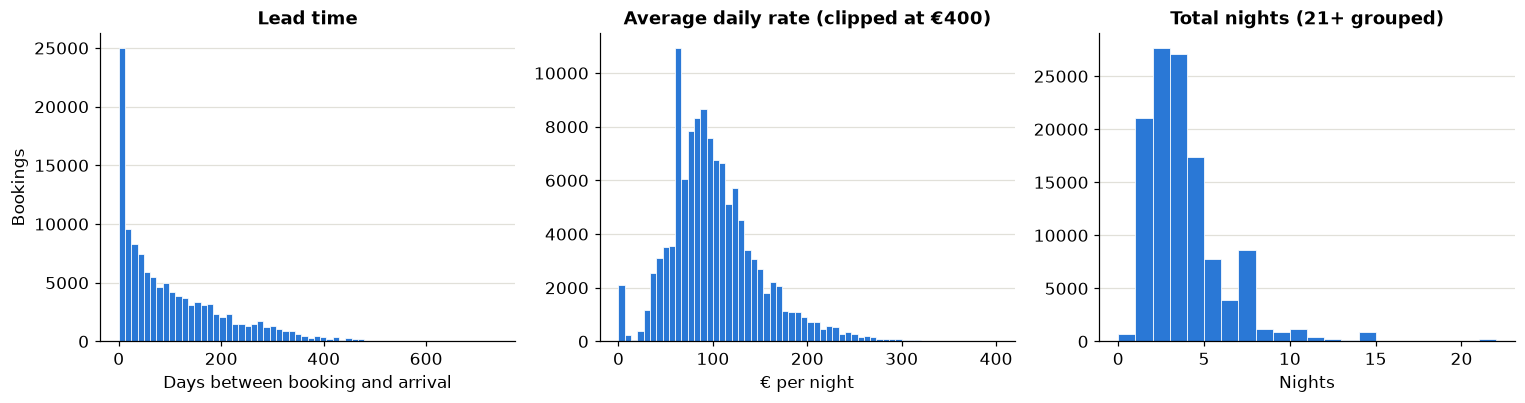

In [21]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))

axes[0].hist(df["lead_time"], bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[0].set(title="Lead time", xlabel="Days between booking and arrival", ylabel="Bookings")

axes[1].hist(df["adr"].clip(0, 400), bins=60, color=BLUE, edgecolor="white", linewidth=0.5)
axes[1].set(title="Average daily rate (clipped at €400)", xlabel="€ per night")

axes[2].hist(total_nights.clip(upper=21), bins=range(0, 23), color=BLUE, edgecolor="white", linewidth=0.5)
axes[2].set(title="Total nights (21+ grouped)", xlabel="Nights")

plt.tight_layout()
plt.show()

In [22]:
def iqr_outlier_summary(data, columns, multiplier=1.5):
    rows = []
    for column in columns:
        q1, q3 = data[column].quantile([0.25, 0.75])
        iqr = q3 - q1
        lower, upper = q1 - multiplier * iqr, q3 + multiplier * iqr
        outside = (data[column] < lower) | (data[column] > upper)
        rows.append({"feature": column, "q1": q1, "q3": q3, "iqr": iqr,
                     "upper_bound": upper, "outliers": outside.sum(),
                     "outlier_percent": 100 * outside.mean()})
    return pd.DataFrame(rows).set_index("feature").sort_values("outlier_percent", ascending=False)

iqr_outlier_summary(df, key_numerical)

,q1,q3,iqr,upper_bound,outliers,outlier_percent
feature,,,,,,
adults,2.00,2.00,0.00,2.00,29710,24.88
booking_changes,0.00,0.00,0.00,0.00,18076,15.14
children,0.00,0.00,0.00,0.00,8590,7.19
required_car_parking_spaces,0.00,0.00,0.00,0.00,7416,6.21
previous_cancellations,0.00,0.00,0.00,0.00,6484,5.43
adr,69.29,126.00,56.71,211.06,3793,3.18
days_in_waiting_list,0.00,0.00,0.00,0.00,3698,3.10
previous_bookings_not_canceled,0.00,0.00,0.00,0.00,3620,3.03
stays_in_week_nights,1.00,3.00,2.00,6.00,3354,2.81


## 6. Which features are related to cancellation?
### 6.1

In [23]:
OVERALL_RATE = df["is_canceled"].mean()


def cancellation_rate(data, column):
    return (data.groupby(column, observed=True)["is_canceled"]
                .agg(bookings="size", cancel_rate="mean"))


def plot_cancellation_rate(table, title, ax, order=None):
    table = table.loc[order] if order is not None else table.sort_values("cancel_rate")
    colors = [ORANGE if rate > OVERALL_RATE else BLUE for rate in table["cancel_rate"]]
    labels = [str(i) for i in table.index]
    ax.barh(labels, table["cancel_rate"] * 100, color=colors, height=0.65)
    for y, (rate, n) in enumerate(zip(table["cancel_rate"], table["bookings"])):
        ax.text(rate * 100 + 1, y, f"{rate:.0%}  (n={n:,})", va="center", fontsize=9)
    ax.axvline(OVERALL_RATE * 100, color=GRAY, linestyle="--", linewidth=1)
    ax.set_xlim(0, 125)
    ax.set_xticks(range(0, 101, 20))
    ax.set_title(title)
    ax.set_xlabel("Cancellation rate (%)")
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)

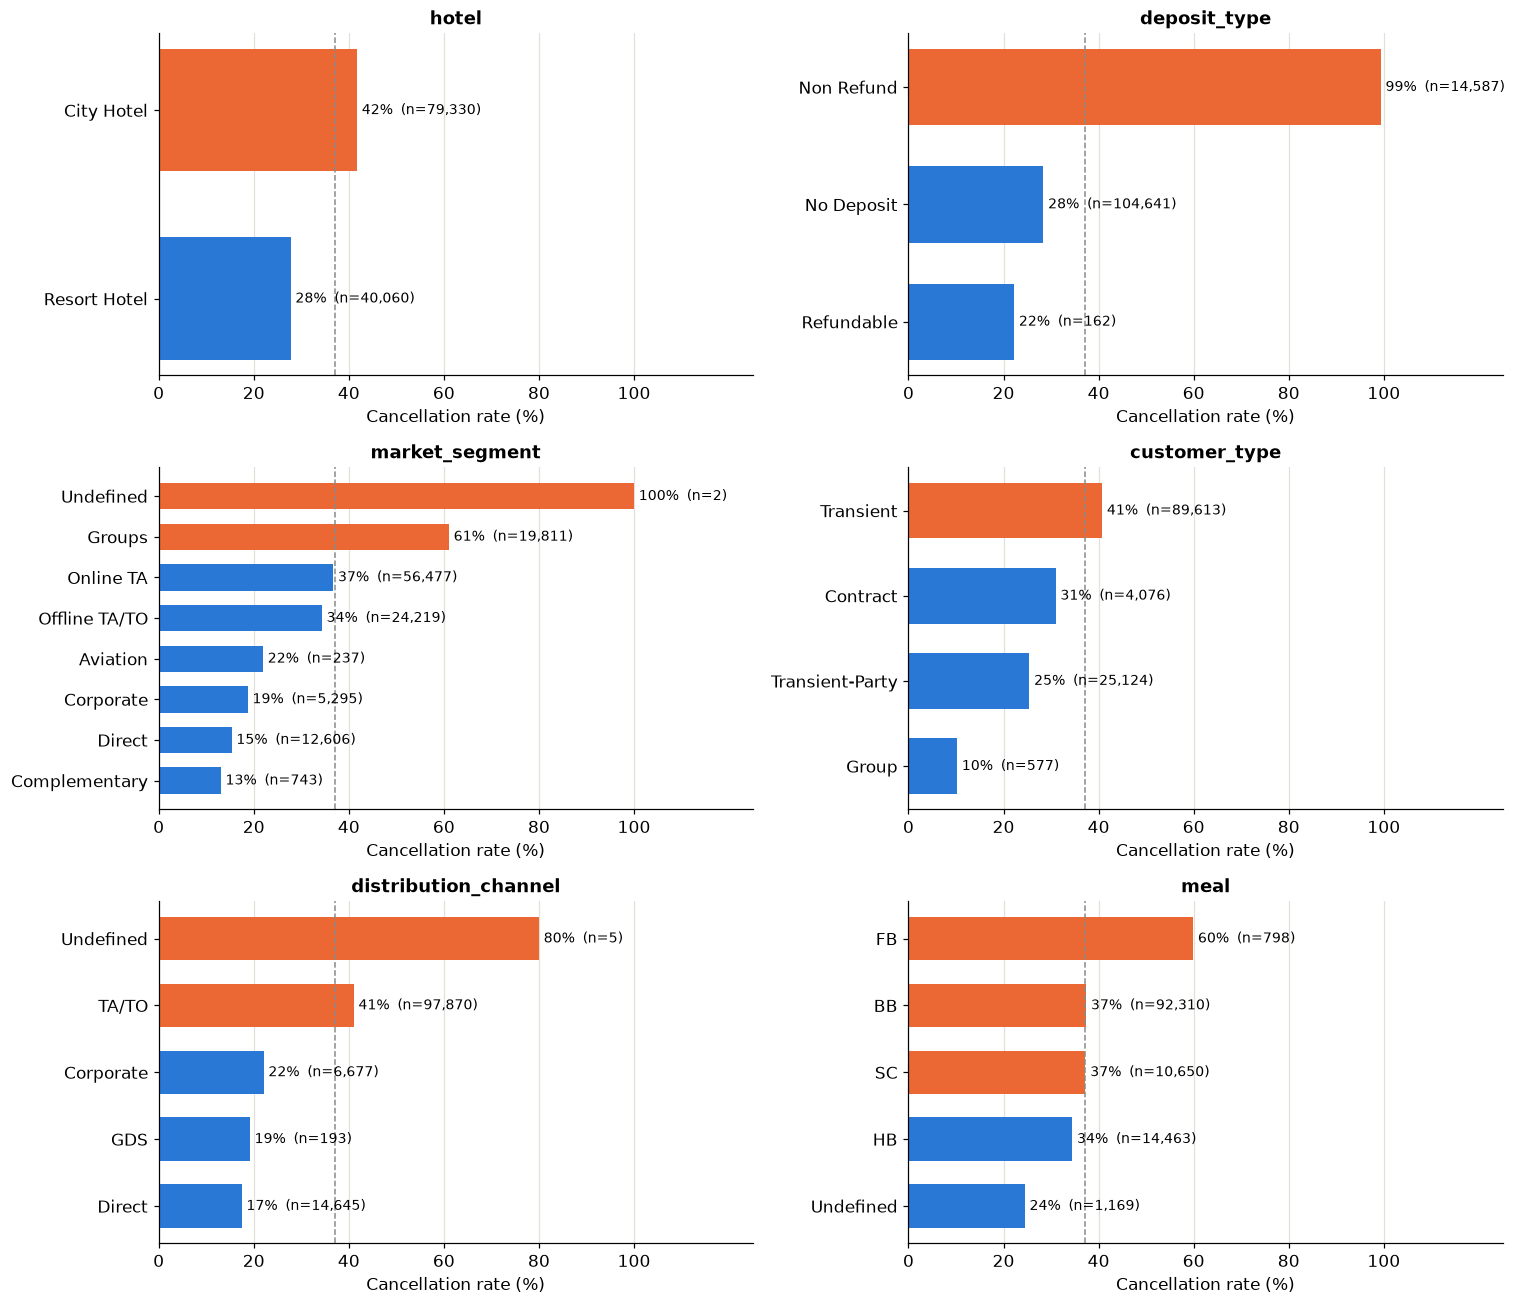

In [24]:
categorical_to_check = ["hotel", "deposit_type", "market_segment",
                        "customer_type", "distribution_channel", "meal"]

fig, axes = plt.subplots(3, 2, figsize=(14, 12))
for column, ax in zip(categorical_to_check, axes.flat):
    plot_cancellation_rate(cancellation_rate(df, column), column, ax)
plt.tight_layout()
plt.show()

In [25]:
pd.crosstab(df["deposit_type"], df["market_segment"], normalize="index").style.format("{:.0%}")

market_segment,Aviation,Complementary,Corporate,Direct,Groups,Offline TA/TO,Online TA,Undefined
deposit_type,,,,,,,,
No Deposit,0%,1%,5%,12%,10%,18%,54%,0%
Non Refund,0%,0%,2%,0%,63%,34%,0%,0%
Refundable,0%,0%,2%,4%,80%,2%,11%,0%


### 6.2
**What we do:** we group each numerical variable into meaningful ranges and plot the cancellation rate of each group.

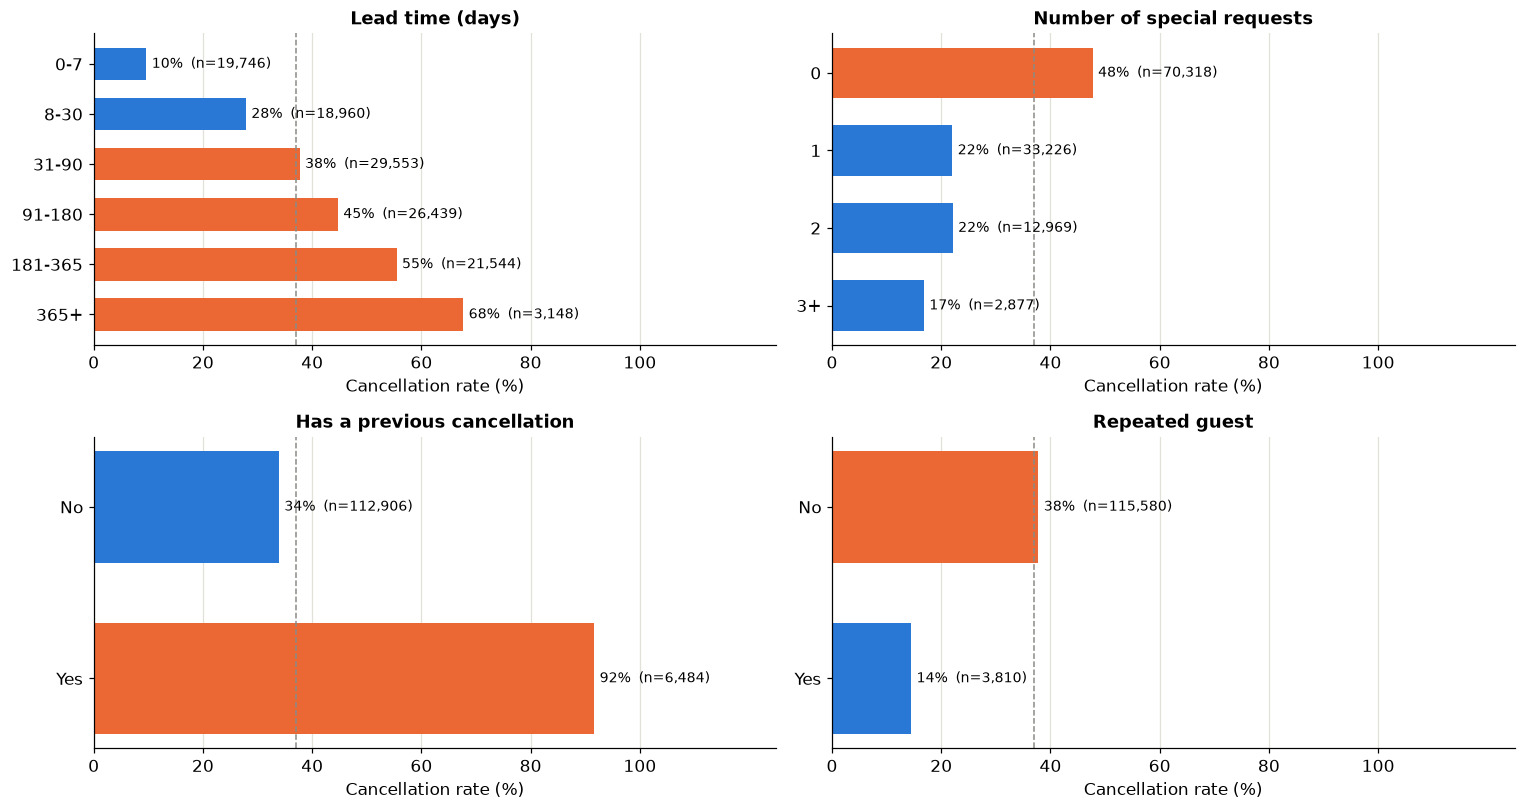

In [26]:
lead_time_bins = pd.cut(df["lead_time"], bins=[-1, 7, 30, 90, 180, 365, 800],
                        labels=["0-7", "8-30", "31-90", "91-180", "181-365", "365+"])
special_requests = df["total_of_special_requests"].clip(upper=3).astype(str).replace("3", "3+")
has_previous_cancellation = df["previous_cancellations"].gt(0).map({False: "No", True: "Yes"})
repeated_guest = df["is_repeated_guest"].map({0: "No", 1: "Yes"})

numerical_views = [
    (lead_time_bins, "Lead time (days)", ["0-7", "8-30", "31-90", "91-180", "181-365", "365+"]),
    (special_requests, "Number of special requests", ["0", "1", "2", "3+"]),
    (has_previous_cancellation, "Has a previous cancellation", ["No", "Yes"]),
    (repeated_guest, "Repeated guest", ["No", "Yes"]),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 7.5))
for (series, title, order), ax in zip(numerical_views, axes.flat):
    table = cancellation_rate(df.assign(group=series), "group")
    plot_cancellation_rate(table, title, ax, order=order[::-1])
plt.tight_layout()
plt.show()

### 6.3 Correlation with the target

For numerical features, the **Pearson correlation** with `is_canceled` measures how strongly the cancellation rate rises (positive) or falls (negative) as the feature grows. It only captures *linear* relationships, so a weak correlation does not mean a feature is useless.

`agent` and `company` are excluded because they are ID codes: a correlation with an ID number has no meaning.

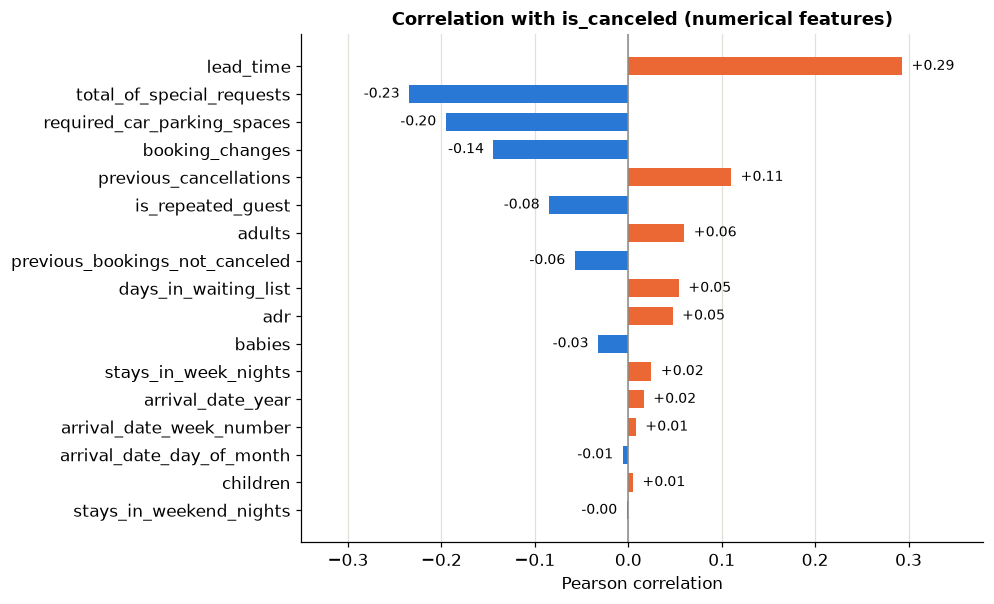

In [27]:
correlation_columns = [c for c in numerical_columns if c not in ("is_canceled", "agent", "company")]
correlations = (df[correlation_columns].corrwith(df["is_canceled"])
                  .sort_values(key=abs, ascending=True))

fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(correlations.index, correlations, color=[ORANGE if v > 0 else BLUE for v in correlations], height=0.65)
for y, value in enumerate(correlations):
    ax.text(value + (0.01 if value >= 0 else -0.01), y, f"{value:+.2f}",
            va="center", ha="left" if value >= 0 else "right", fontsize=9)
ax.axvline(0, color=GRAY, linewidth=1)
ax.set_xlim(-0.35, 0.38)
ax.set_title("Correlation with is_canceled (numerical features)")
ax.set_xlabel("Pearson correlation")
ax.grid(axis="x")
ax.grid(axis="y", visible=False)
plt.show()

### 6.4 Strength of association for categorical features

Correlation does not work for text categories. Instead we use **Cramér's V**, which measures how strongly two categorical variables are associated: **0 = no association, 1 = one determines the other**.

Caveat: features with very many categories (`country`, `agent`) tend to get somewhat inflated values.

In [29]:
def cramers_v(x, y):
    table = pd.crosstab(x, y)
    chi2 = chi2_contingency(table)[0]
    return np.sqrt(chi2 / (table.values.sum() * (min(table.shape) - 1)))


association_columns = ["reservation_status", "deposit_type", "agent", "country", "market_segment",
                       "assigned_room_type", "distribution_channel", "customer_type", "hotel",
                       "reserved_room_type", "arrival_date_month", "meal", "company"]

associations = pd.Series({
    column: cramers_v(df[column].astype(object).fillna("None"), df["is_canceled"])
    for column in association_columns
}).sort_values(ascending=False).to_frame("cramers_v")
associations

,cramers_v
reservation_status,1.00
deposit_type,0.48
agent,0.39
country,0.36
market_segment,0.27
assigned_room_type,0.20
distribution_channel,0.18
company,0.14
hotel,0.14
customer_type,0.14


### Interpretation

**Strongest signals:**
- **Deposit type:** almost every **non-refundable** booking is canceled (99%). This is counter-intuitive, but the crosstab explains it: non-refundable bookings are mostly **Groups** and **offline travel agency** bookings, i.e. blocks of rooms reserved by agencies and released later.
- **Lead time** is the strongest numerical feature (correlation +0.29): bookings made within a week are canceled 10% of the time, bookings made more than a year ahead 68%.
- **Previous cancellations:** customers who canceled before cancel again far more often (92% vs 34%).
- **Special requests** (−0.23): customers with at least one special request cancel much less (about 20% vs 48%); they seem committed to the stay.
- **Market segment:** Groups (61%) cancel most, Direct (15%) and Corporate (19%) least.

**Weak signals:** `hotel` (Cramér's V 0.14; City 42% vs Resort 28%), `meal` and the arrival month.

**Be careful with small groups:** the *Undefined* market segment shows 100% cancellation, but it contains only **2 bookings**. Always read a rate together with its group size (`n`).

**Important:** after removing `reservation_status` (see Section 7), **no single feature determines the outcome**. The model has to combine many moderate signals.

**Decisions:**
- Keep all of these features.
- `reservation_status` has V = 1.00: it is a copy of the target (Section 7).

## 7. Data leakage

### 7.1 Definite leakage: reservation status

In [30]:
pd.crosstab(df["reservation_status"], df["is_canceled"])

is_canceled,0,1
reservation_status,,
Canceled,0,43017
Check-Out,75166,0
No-Show,0,1207


`reservation_status` is the outcome itself: *Canceled* and *No-Show* are always `is_canceled = 1`, *Check-Out* is always 0. `reservation_status_date` is the date of that outcome, so it leaks too.

### 7.2 Suspected leakage: information that may be recorded at check-in

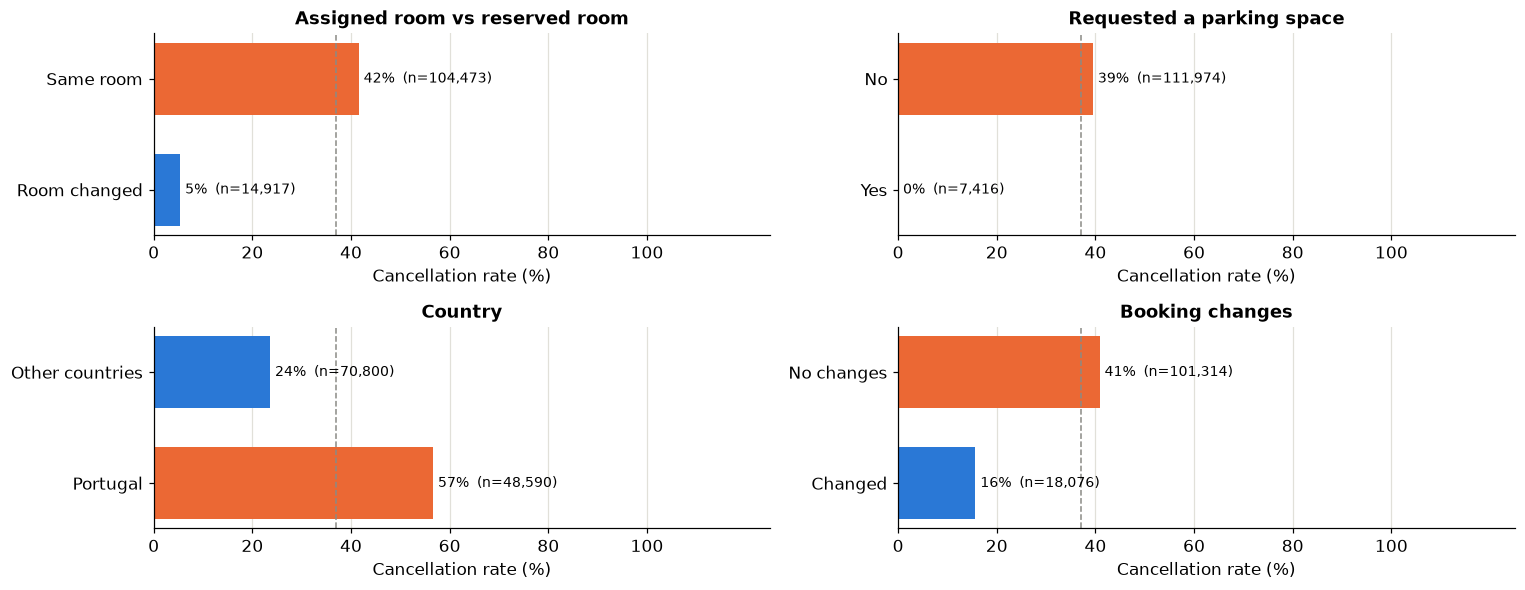

In [31]:
room_changed = (df["reserved_room_type"] != df["assigned_room_type"]).map({False: "Same room", True: "Room changed"})
requested_parking = df["required_car_parking_spaces"].gt(0).map({False: "No", True: "Yes"})
portugal = df["country"].eq("PRT").map({False: "Other countries", True: "Portugal"})
changed_booking = df["booking_changes"].gt(0).map({False: "No changes", True: "Changed"})

suspects = [
    (room_changed, "Assigned room vs reserved room", ["Same room", "Room changed"]),
    (requested_parking, "Requested a parking space", ["No", "Yes"]),
    (portugal, "Country", ["Other countries", "Portugal"]),
    (changed_booking, "Booking changes", ["No changes", "Changed"]),
]

fig, axes = plt.subplots(2, 2, figsize=(14, 5.5))
for (series, title, order), ax in zip(suspects, axes.flat):
    plot_cancellation_rate(cancellation_rate(df.assign(group=series), "group"), title, ax, order=order[::-1])
plt.tight_layout()
plt.show()

### Interpretation

| Feature | Observation | Possible reason |
|---|---|---|
| `assigned_room_type` | Room changed → 5% canceled; same room → 42% | Rooms are assigned at check-in; a canceled booking never gets reassigned |
| `required_car_parking_spaces` | **0%** of bookings with a parking request were canceled | Parking is probably recorded on arrival |
| `country` | Portugal 57% vs others 24% | Country may only be confirmed at check-in (partly also explained by non-refundable group bookings) |
| `booking_changes` | Changed bookings cancel less | The value can grow over time, after the booking was made |

**Decisions:**
- **Remove** `reservation_status` and `reservation_status_date`.
- **Ablation experiment** for the suspected features: train every model with and without them and compare. A large drop without them supports the leakage suspicion.

## 8. Time patterns

**What we do:** check how bookings, cancellations and prices change over the arrival months and years.

**Why:** if behavior changes over time, a model trained on past data may perform worse on future bookings. This decides how we split the data and which date columns we use.

In [32]:
MONTH_ORDER = ["January", "February", "March", "April", "May", "June", "July",
               "August", "September", "October", "November", "December"]
arrival_date = pd.to_datetime(dict(
    year=df["arrival_date_year"],
    month=df["arrival_date_month"].map({m: i for i, m in enumerate(MONTH_ORDER, start=1)}),
    day=df["arrival_date_day_of_month"],
))
print(f"Arrivals from {arrival_date.min():%d %B %Y} to {arrival_date.max():%d %B %Y}\n")

cancellation_rate(df, "arrival_date_year")

Arrivals from 01 July 2015 to 31 August 2017



,bookings,cancel_rate
arrival_date_year,,
2015,21996,0.37
2016,56707,0.36
2017,40687,0.39


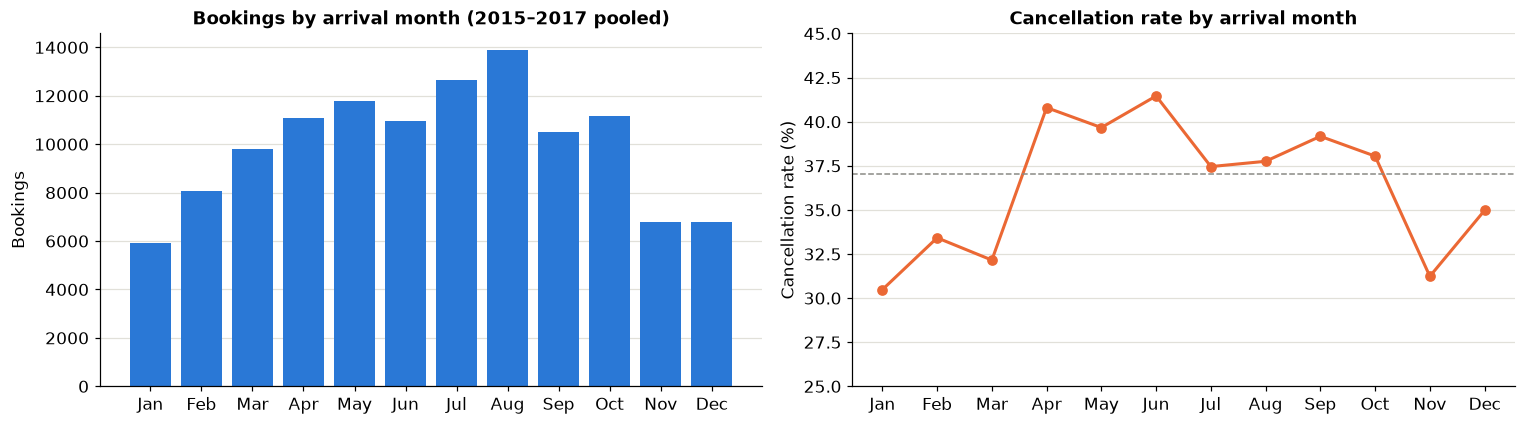

In [33]:
monthly = cancellation_rate(df, "arrival_date_month").loc[MONTH_ORDER]

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
axes[0].bar([m[:3] for m in MONTH_ORDER], monthly["bookings"], color=BLUE)
axes[0].set(title="Bookings by arrival month (2015–2017 pooled)", ylabel="Bookings")

axes[1].plot([m[:3] for m in MONTH_ORDER], monthly["cancel_rate"] * 100, marker="o", color=ORANGE, linewidth=2)
axes[1].axhline(OVERALL_RATE * 100, color=GRAY, linestyle="--", linewidth=1)
axes[1].set(title="Cancellation rate by arrival month", ylabel="Cancellation rate (%)", ylim=(25, 45))
plt.tight_layout()
plt.show()

In [34]:
summer = df[df["arrival_date_month"].isin(["July", "August"])]
drift = summer.groupby("arrival_date_year")[["lead_time", "adr", "is_canceled"]].mean()
drift.columns = ["mean_lead_time_days", "mean_adr_eur", "cancel_rate"]
drift

,mean_lead_time_days,mean_adr_eur,cancel_rate
arrival_date_year,,,
2015,110.46,102.55,0.43
2016,122.41,134.63,0.34
2017,145.67,153.24,0.37


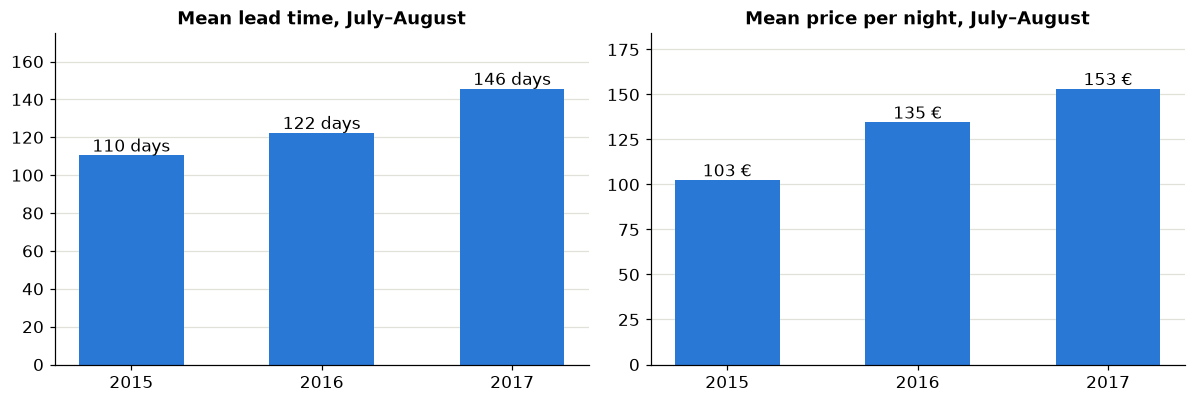

In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
years = drift.index.astype(str)
for ax, column, title, unit in [
    (axes[0], "mean_lead_time_days", "Mean lead time, July–August", "days"),
    (axes[1], "mean_adr_eur", "Mean price per night, July–August", "€"),
]:
    bars = ax.bar(years, drift[column], color=BLUE, width=0.55)
    for bar, value in zip(bars, drift[column]):
        ax.text(bar.get_x() + bar.get_width() / 2, value + 2, f"{value:.0f} {unit}", ha="center")
    ax.set_ylim(0, drift[column].max() * 1.2)
    ax.set_title(title)
plt.tight_layout()
plt.show()

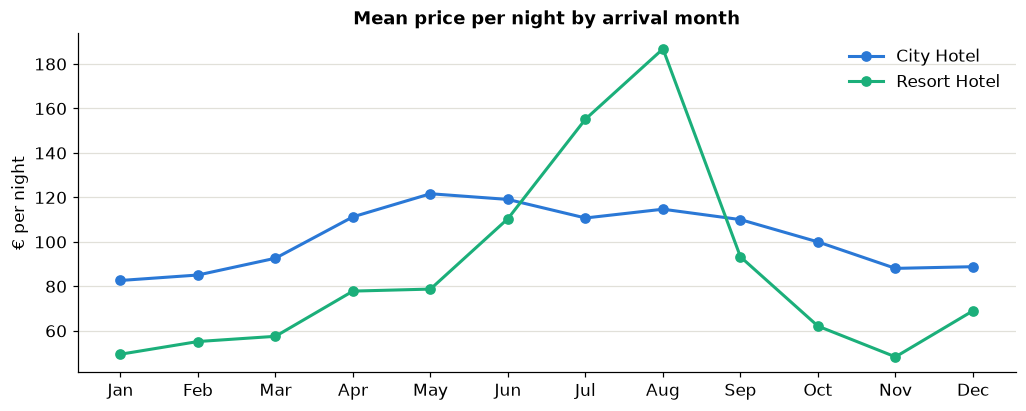

In [36]:
monthly_price = df.groupby(["arrival_date_month", "hotel"])["adr"].mean().unstack().loc[MONTH_ORDER]

fig, ax = plt.subplots(figsize=(11, 4))
for hotel, color in [("City Hotel", BLUE), ("Resort Hotel", AQUA)]:
    ax.plot([m[:3] for m in MONTH_ORDER], monthly_price[hotel], marker="o", color=color, linewidth=2, label=hotel)
ax.set(title="Mean price per night by arrival month", ylabel="€ per night")
ax.legend(frameon=False)
plt.show()

### Interpretation

- Arrivals run from **1 July 2015 to 31 August 2017**; only 2016 is a complete year.
- The **cancellation rate is fairly stable** across years (37%, 36%, 39%) but shows **seasonality**: lower from November to March (about 30–35%), higher from April to October (about 37–42%).
- Feature values **drift**: for the same summer months, mean lead time rose from about 110 to 146 days and mean price from about €103 to €153 between 2015 and 2017.
- Prices are strongly seasonal, especially at the resort hotel (summer peak).

**Decisions:**
- **Do not use `arrival_date_year` as a feature**: a model cannot generalize from "2016" to a year it has never seen.
- Keep `arrival_date_month` (seasonality). Drop `arrival_date_week_number` and `arrival_date_day_of_month` (almost no relationship with the target); derive the **arrival weekday** instead.
- Add a **temporal test**: train on 2015–2016, test on 2017, and compare with the random split. Because of the drift we expect a lower score.

## 9. Categorical features with many values

**What we do:** count the distinct values of `country`, `agent` and `company`, and check whether the *specific* agent matters.

**Why:** one-hot encoding creates one column per value. With hundreds of values, most of these columns would be almost empty.

In [37]:
high_cardinality = ["country", "agent", "company"]
pd.DataFrame({
    "distinct_values": df[high_cardinality].nunique(),
    "values_with_fewer_than_10_bookings": [(df[c].value_counts() < 10).sum() for c in high_cardinality],
    "values_with_one_booking": [(df[c].value_counts() == 1).sum() for c in high_cardinality],
})

,distinct_values,values_with_fewer_than_10_bookings,values_with_one_booking
country,177,81,30
agent,333,121,50
company,352,233,80


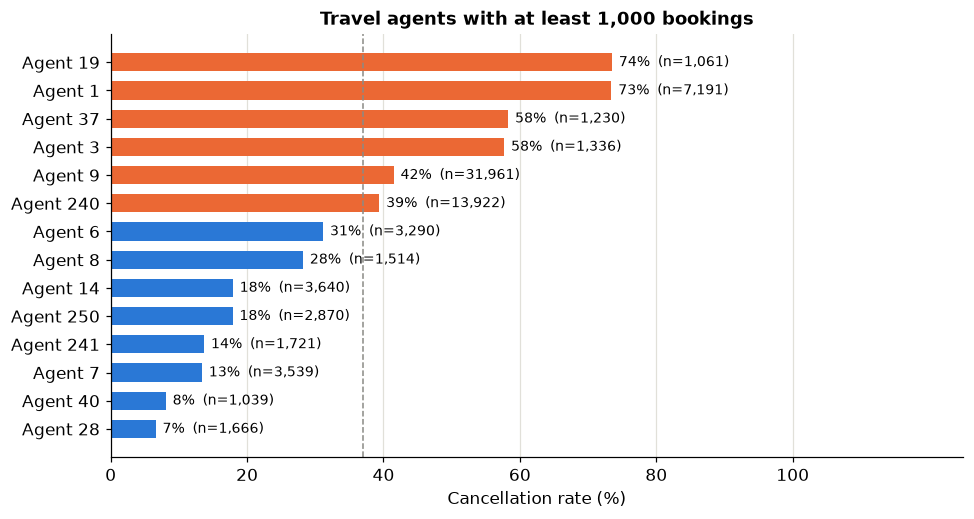

In [38]:
agents = cancellation_rate(df.dropna(subset=["agent"]).assign(agent=lambda d: "Agent " + d["agent"].astype(int).astype(str)), "agent")
large_agents = agents[agents["bookings"] >= 1000]

fig, ax = plt.subplots(figsize=(10, 5))
plot_cancellation_rate(large_agents, "Travel agents with at least 1,000 bookings", ax)
plt.show()

### Interpretation

- `country`, `agent` and `company` have **177, 333 and 352 distinct values**, many of them with fewer than 10 bookings.
- The **identity** of the agent matters: among large agents, cancellation rates range from below 10% to above 70%. Reducing `agent` to "has an agent: yes/no" would throw this information away.

**Decisions:**
- Treat `agent` and `company` as **categories**, not numbers.
- Compare two encodings: **one-hot encoding with rare values grouped as "Other"**, and **target encoding** (computed only on training data, inside each cross-validation fold, to avoid leakage).

## 10. Summary: from findings to decisions

| # | Finding | Decision |
|---|---|---|
| 1 | Binary target, 37% canceled (27.5% without duplicates) | Use F1 and ROC-AUC; stratified splits |
| 2 | `company` 94% and `agent` 14% missing; missing means "none" | Fill with a `"None"` category |
| 3 | `country` 0.4% and `children` 4 rows missing | Fill with `"Unknown"` and 0 |
| 4 | 31,994 exact duplicate rows (26.8%) | Remove before splitting; optional grouped-split experiment |
| 5 | ~2,000 bookings with zero guests, zero nights or price ≤ 0; one €5,400 price | Remove |
| 6 | Skewed features; IQR flags many valid values | Keep values; standardize for linear models and neural networks |
| 7 | `reservation_status` / `_date` reveal the outcome | Remove (leakage) |
| 8 | Room assignment, parking, country, booking changes may be recorded at check-in | Ablation: train with and without |
| 9 | Deposit type, lead time, previous cancellations, special requests, segment are strong signals | Keep; check them in feature importance analysis |
| 10 | Hotel type only weakly related (V = 0.14) | Keep as a normal feature |
| 11 | `agent` / `company` are ID codes with hundreds of values | Treat as categorical; one-hot with rare grouping vs. target encoding |
| 12 | Seasonality and drift in lead time and price | Drop year as a feature, keep month, add weekday; temporal test on 2017 |
| 13 | New information can be derived | `total_nights`, `total_guests`, `arrival_weekday` |